# 极客项目 ch07：照片马赛克

对应《Python Playground》第 7 章（Photomosaics）。原书 argparse/main 改为演示 cell：合成目标图与 24 张小块图库（seed=2030），跑完整 `createPhotomosaic` 流程。

In [1]:
# ===== 公共设置 =====
%matplotlib inline
import os
import random
import tempfile
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

random.seed(2030)
np.random.seed(2030)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False


## 书 7.3.1 读入小块图像

遍历目录、逐个 `Image.open` 并 `load()`，无效文件跳过。

In [2]:
# ===== 书 7.3.1 节 getImages() =====
def getImages(imageDir):
    """given a directory of images, return a list of Images"""
    files = os.listdir(imageDir)
    images = []
    for file in files:
        filePath = os.path.abspath(os.path.join(imageDir, file))
        try:
            fp = open(filePath, "rb")
            im = Image.open(fp)
            images.append(im)
            # force loading image data from file
            im.load()
            fp.close()
        except Exception:
            # skip
            print("Invalid image: %s" % (filePath,))
    return images


## 书 7.3.2 计算平均颜色值

numpy 二维化后按行摊平求 (r, g, b) 均值。

In [3]:
# ===== 书 7.3.2 节 getAverageRGB() =====
def getAverageRGB(image):
    """Given PIL Image, return average value of color as (r, g, b)"""
    im = np.array(image)
    w, h, d = im.shape
    return tuple(np.average(im.reshape(w*h, d), axis=0))


## 书 7.3.3 分割目标图像

按 (行 m, 列 n) 网格裁块，返回 m×n 个小图。

In [4]:
# ===== 书 7.3.3 节 splitImage() =====
def splitImage(image, size):
    """Given Image and dims (rows, cols) returns an m*n list of Images"""
    W, H = image.size[0], image.size[1]
    m, n = size
    w, h = int(W/n), int(H/m)
    imgs = []
    for j in range(m):
        for i in range(n):
            imgs.append(image.crop((i*w, j*h, (i+1)*w, (j+1)*h)))
    return imgs


## 书 7.3.4 寻找小块的最佳匹配

RGB 距离平方最近的小块胜出。

In [5]:
# ===== 书 7.3.4 节 getBestMatchIndex() =====
def getBestMatchIndex(input_avg, avgs):
    """return index of best Image match based on RGB value distance"""
    avg = input_avg
    index = 0
    min_index = 0
    min_dist = float("inf")
    for val in avgs:
        dist = ((val[0] - avg[0])*(val[0] - avg[0]) +
                (val[1] - avg[1])*(val[1] - avg[1]) +
                (val[2] - avg[2])*(val[2] - avg[2]))
        if dist < min_dist:
            min_dist = dist
            min_index = index
        index += 1
    return min_index


## 书 7.3.5 创建图像网格

把匹配到的小块按 (m, n) 拼回大图（取最大宽高，不假设子图同尺寸）。

In [6]:
# ===== 书 7.3.5 节 createImageGrid() =====
def createImageGrid(images, dims):
    """Given a list of images and a grid size (m, n), create a grid of images."""
    m, n = dims
    # sanity check
    assert m*n == len(images)
    # 取最大宽高，不假设所有子图同尺寸
    width = max([img.size[0] for img in images])
    height = max([img.size[1] for img in images])
    grid_img = Image.new('RGB', (n*width, m*height))
    for index in range(len(images)):
        row = int(index/n)
        col = index - n*row
        grid_img.paste(images[index], (col*width, row*height))
    return grid_img


## 书 7.3.6 创建照片马赛克

分割 → 逐块匹配 → 拼网格；`reuse_images=True` 允许重复使用小块。

In [7]:
# ===== 书 7.3.6 节 createPhotomosaic() =====
def createPhotomosaic(target_image, input_images, grid_size,
                      reuse_images=True):
    """Creates photomosaic given target and input images."""
    print('splitting input image...')
    target_images = splitImage(target_image, grid_size)

    print('finding image matches...')
    output_images = []
    count = 0
    batch_size = int(len(target_images)/10)

    # calculate input image averages
    avgs = []
    for img in input_images:
        avgs.append(getAverageRGB(img))

    for img in target_images:
        avg = getAverageRGB(img)
        match_index = getBestMatchIndex(avg, avgs)
        output_images.append(input_images[match_index])
        # user feedback
        if count > 0 and batch_size > 10 and count % batch_size == 0:  # Py3：is 0→==0
            print('processed %d of %d...' % (count, len(target_images)))
        count += 1
        # remove selected image from input if flag set
        if not reuse_images:
            input_images.pop(match_index)  # 原书 bug：input_images.remove(match) 中 match 未定义

    print('creating mosaic...')
    mosaic_image = createImageGrid(output_images, grid_size)
    return mosaic_image


## 演示：合成目标图 + 小块图库

书 7.3.8 的 resize_input（`thumbnail` 控制块尺寸）一并演示；目标图为对角渐变 + 深色圆，块库为 24 张 32×32 随机双色渐变。

读取小块：24 张
max tile dims: (21, 12)
splitting input image...
finding image matches...
processed 19 of 192...
processed 38 of 192...
processed 57 of 192...
processed 76 of 192...
processed 95 of 192...
processed 114 of 192...
processed 133 of 192...
processed 152 of 192...
processed 171 of 192...
processed 190 of 192...
creating mosaic...
saved output to C:\Users\17272\AppData\Local\Temp\pg_ch07_3x3eczre\mosaic.png


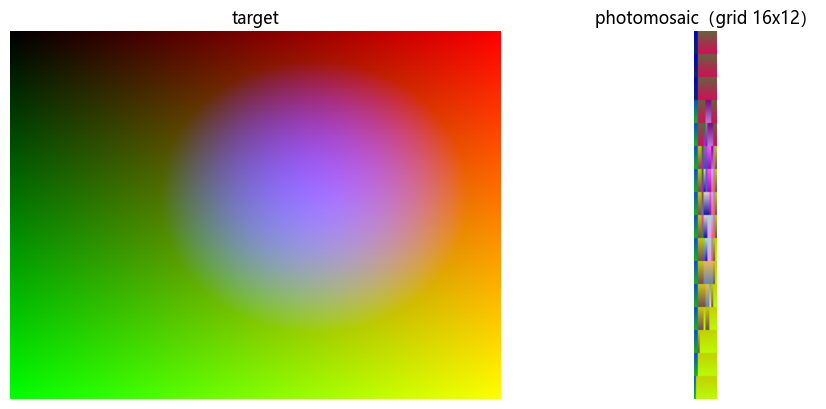

In [8]:
# ===== 演示：合成目标图与块库，跑 createPhotomosaic（书 7.3.8 的 resize 一并演示）=====
random.seed(2030)
np.random.seed(2030)

work = tempfile.mkdtemp(prefix='pg_ch07_')
tile_dir = os.path.join(work, 'tiles')
os.makedirs(tile_dir)

# 小块图库：24 张 32×32 随机双色垂直渐变图
for i in range(24):
    c1 = np.random.randint(0, 256, 3)
    c2 = np.random.randint(0, 256, 3)
    g = np.linspace(0, 1, 32).reshape(32, 1, 1)
    arr = (c1.reshape(1, 1, 3)*(1-g) + c2.reshape(1, 1, 3)*g).astype(np.uint8)
    Image.fromarray(arr, 'RGB').save(os.path.join(tile_dir, 'tile%02d.png' % i))

# 目标图：256×192 对角渐变 + 深色圆
xx, yy = np.meshgrid(np.linspace(0, 1, 256), np.linspace(0, 1, 192))
r2 = (xx-0.62)**2/0.10 + (yy-0.45)**2/0.14
arr = np.stack([255*xx, 255*yy, 255*np.clip(1-r2, 0, 1)], axis=2).astype(np.uint8)
target = Image.fromarray(arr, 'RGB')
target_path = os.path.join(work, 'target.png')
target.save(target_path)

input_images = getImages(tile_dir)
print('读取小块：%d 张' % len(input_images))
random.shuffle(input_images)

grid_size = (16, 12)
dims = (int(target.size[0]/grid_size[1]), int(target.size[1]/grid_size[0]))  # 书 7.3.8
print('max tile dims: %s' % (dims,))
for im in input_images:
    im.thumbnail(dims)

mosaic = createPhotomosaic(target, input_images, grid_size, reuse_images=True)
mosaic_path = os.path.join(work, 'mosaic.png')
mosaic.save(mosaic_path, 'PNG')
print('saved output to %s' % mosaic_path)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
axes[0].imshow(target); axes[0].set_title('target'); axes[0].axis('off')
axes[1].imshow(mosaic); axes[1].set_title('photomosaic（grid %dx%d）' % grid_size); axes[1].axis('off')
plt.tight_layout()
plt.show()